**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061 - Operaciones de aprendizaje automático**

Tecnológico de Monterrey

Profesor: Dr. Iván Reyes Amezcua

**Semana 3**
Modelo base para predicción de abandono de clientes (Telco Churn): EDA, limpieza y registro en MLflow

---

*   NOMBRE: GERARDO CARREÑO GARCÍA
*   MATRÍCULA: A01797668

**Objetivo:** Explorar el dataset de abandono de clientes (Telco Churn): carga, descripción, análisis univariado y bivariado. La limpieza y el modelado viven en el paquete `experimentacion_mlflow_abandono_clientes`.


In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

#Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

#Se usa el paquete del proyecto para cargar los datos
from experimentacion_mlflow_abandono_clientes.dataset import cargar_datos

# Paso 1: Carga y descripción del dataset

### 1.1 Ingesta de Datos
Procedemos a importar el histórico de clientes (`WA_Fn-UseC_-Telco-Customer-Churn.csv`), estableciendo el identificador único del cliente (`customerID`) como índice para evitar fugas de información y facilitar la manipulación del set de datos.

In [3]:
#Se carga el dataset desde el paquete (data/raw)
churn_df = cargar_datos()
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Dimensiones del Dataset
El conjunto de datos consta de 7,043 clientes únicos y 20 características predictoras (demográficas, de cuenta y servicios). Este volumen inicial es suficiente para un modelo Baseline, aunque es necesario mantener bajo observación el balance de las clases.


In [5]:
#Número de registros y variables del dataset
print("Número de registros:", churn_df.shape[0])
print("Número de variables:", churn_df.shape[1])

Número de registros: 7043
Número de variables: 20


In [6]:
#Se utiliza el método info() del dataframe para obtener el resumen de los tipos de datos
churn_df.info()

<class 'pandas.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 

In [7]:
#Se revisan los valores únicos de cada columna para identificar cuáles son categóricas y cuáles numéricas
churn_df.nunique()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

# Paso 2: Análisis exploratorio de datos (EDA)

### 2.1 Coerción de Tipos de Datos
Detectamos anomalías iniciales en los tipos de datos asignados. Para el Análisis Exploratorio, forzaremos temporalmente la conversión de variables como `TotalCharges` a numéricas y posteriormente categorizaremos adecuadamente campos como `SeniorCitizen`, asegurando así métricas descriptivas válidas.


In [8]:
#Se crea una copia para el EDA y se convierte TotalCharges a numérica (los valores que no se pueden convertir quedan como NaN)
eda_df = churn_df.copy()
eda_df['TotalCharges'] = pd.to_numeric(eda_df['TotalCharges'], errors='coerce')

#Se crean dos listas con los nombres de las variables numéricas y categóricas (sin la variable de salida)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in eda_df.columns if col not in num_cols + ['Churn']]
print(num_cols)
print(cat_cols)

['tenure', 'MonthlyCharges', 'TotalCharges']
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Análisis univariado

### 2.2 Estadísticas descriptivas de las variables numéricas

Analizamos el comportamiento de la tenencia (`tenure`) y los cargos (mensuales y totales). El cálculo de asimetría y curtosis nos permitirá identificar desviaciones significativas de la normalidad que podrían afectar ciertos algoritmos predictivos.

In [9]:
#Se obtiene la simetría y curtosis de las variables numéricas y se agregan a las estadísticas descriptivas
simetria = eda_df[num_cols].skew()
curtosis = eda_df[num_cols].kurtosis()

describe_churn_df = eda_df[num_cols].describe().T
describe_churn_df['simetria'] = simetria
describe_churn_df['curtosis'] = curtosis
describe_churn_df

,count,mean,std,min,25%,50%,75%,max,simetria,curtosis
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0.239540,-1.387372
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,-0.220524,-1.257260
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,0.961642,-0.231799


### 2.3 Distribución y Detección Visual de Anomalías (Numéricas)
Al comparar la distribución real contra una curva normal teórica (KDE), podemos observar agrupamientos (por ejemplo, clientes con tenencia muy corta). Los diagramas de caja (boxplots) nos darán un primer indicio de valores atípicos (outliers).

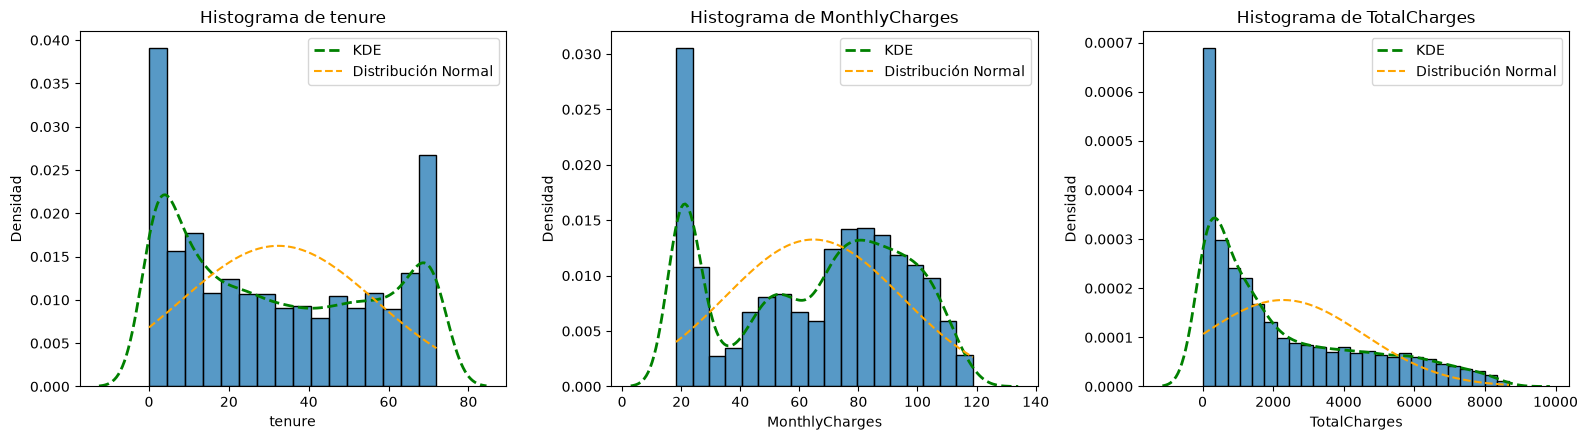

In [10]:
#Se genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(num_cols):
    datos = eda_df[col].dropna()
    sns.histplot(x=datos, ax=axes[i], stat='density')
    sns.kdeplot(x=datos, ax=axes[i], color='green', linewidth=2, label='KDE', ls="dashed")
    x_vals = np.linspace(datos.min(), datos.max(), 1000)
    normal_ref = norm.pdf(x_vals, loc=datos.mean(), scale=datos.std())
    axes[i].plot(x_vals, normal_ref, color='orange', label='Distribución Normal', ls="dashed")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Densidad')
    axes[i].set_title(f'Histograma de {col}')
    axes[i].legend()

plt.tight_layout()
plt.show()

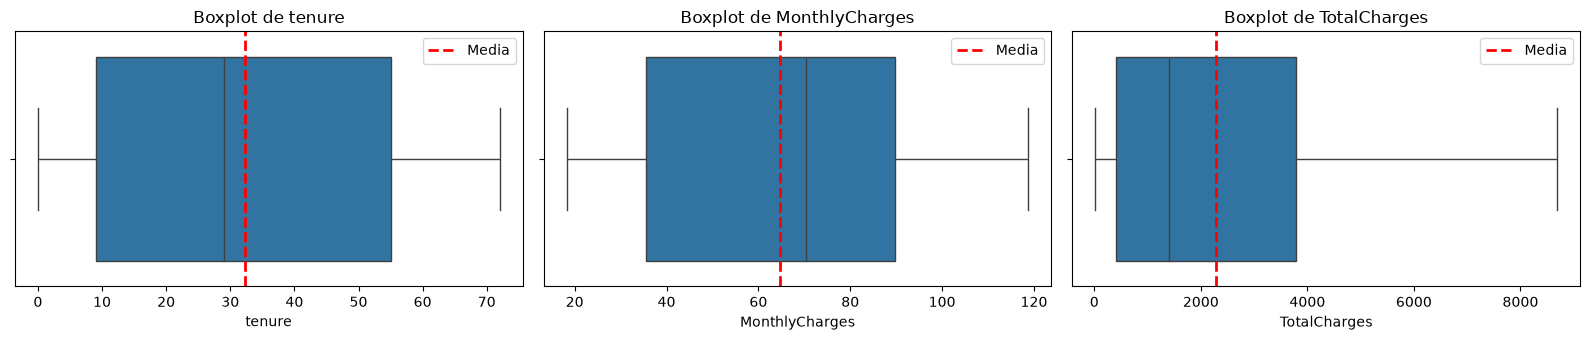

In [11]:
#Se crea un gráfico de boxplot individual para cada variable numérica que incluye la media
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))

for i, col in enumerate(num_cols):
    sns.boxplot(data=eda_df, x=col, ax=axes[i])
    axes[i].axvline(eda_df[col].mean(), color='red', linestyle='dashed', linewidth=2, label='Media')
    axes[i].legend()
    axes[i].set_title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

### 2.4 Composición del Portafolio de Clientes (Variables Categóricas)
Exploramos la adopción de servicios y características demográficas. Al evaluar la cardinalidad de cada variable, confirmamos que la mayoría presenta pocos niveles (e.g., binarias o de 3 a 4 opciones), lo cual hace viable una estrategia de *One-Hot Encoding* sin generar dispersión severa (sparsity) en los datos.

In [12]:
#Se obtienen las estadísticas descriptivas de las variables categóricas
eda_df[cat_cols + ['Churn']].astype('object').describe()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3555,5901,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


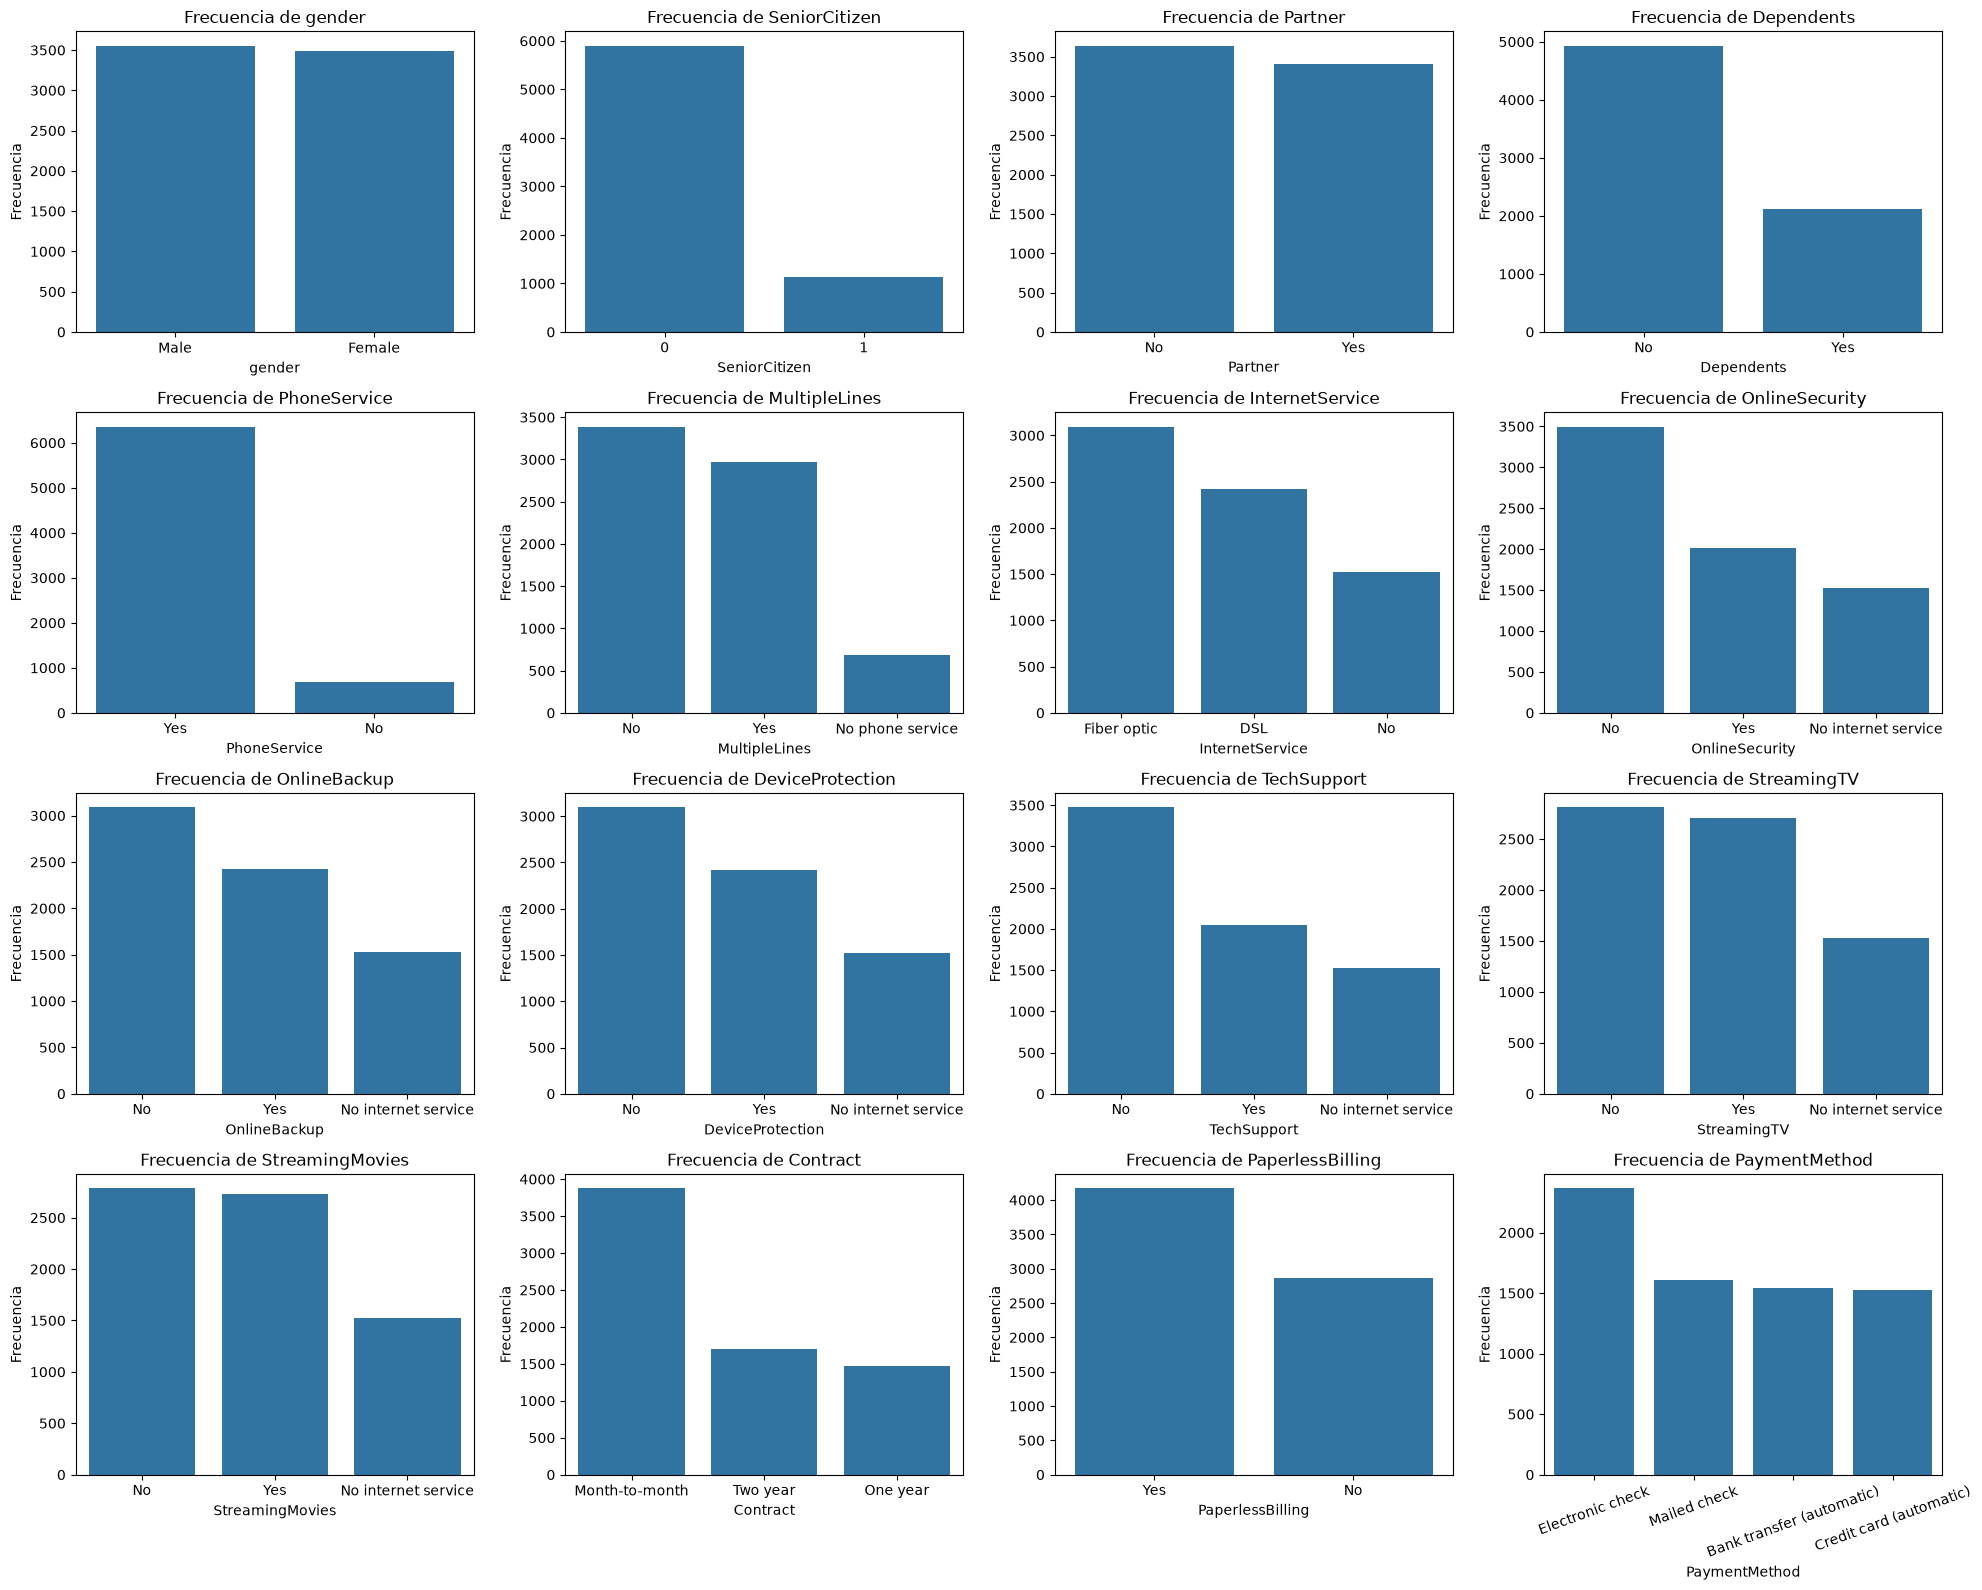

In [13]:
#Se genera un gráfico de barras para cada variable categórica
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    conteo = eda_df[col].value_counts()
    sns.barplot(x=conteo.index, y=conteo.values, ax=axes[i])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')
    axes[i].set_title(f'Frecuencia de {col}')
    if col == 'PaymentMethod':
        axes[i].tick_params(axis='x', labelrotation=20)

plt.tight_layout()
plt.show()

### 2.5 Distribución del Target (`Churn`)
El dataset presenta un desbalance evidente a favor de la retención: **73.5% de los clientes se mantienen y 26.5% han abandonado.** Este desbalance es crítico, pues dictará que la métrica de evaluación primaria no sea el Accuracy, sino ROC-AUC y F1-Score.

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

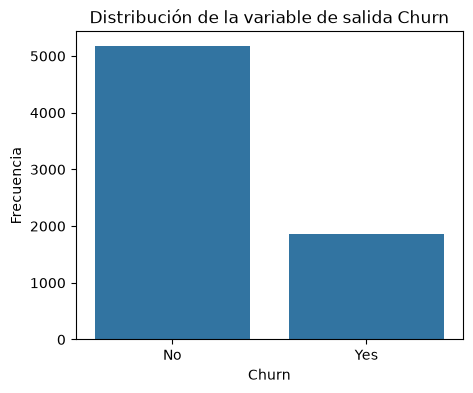

In [14]:
#Se analiza la distribución de la variable de salida Churn
display(eda_df['Churn'].value_counts())
display(eda_df['Churn'].value_counts(normalize=True))

conteo = eda_df['Churn'].value_counts()
plt.figure(figsize=(5, 4))
sns.barplot(x=conteo.index, y=conteo.values)
plt.title('Distribución de la variable de salida Churn')
plt.ylabel('Frecuencia')
plt.show()

## Análisis bivariado

### 2.6 Correlación Numérica (Multicolinealidad)
Al cruzar las variables continuas, observamos la correlación esperada entre `tenure` (antigüedad) y `TotalCharges` (cargos totales acumulados). Deberemos considerar si este nivel de correlación introduce ruido en modelos lineales como la Regresión Logística.

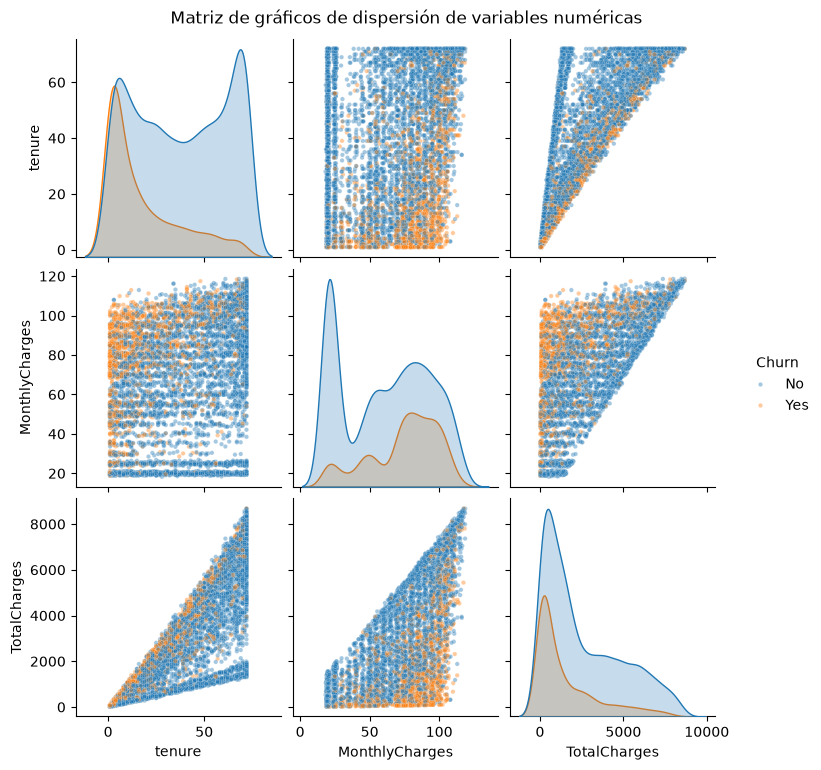

In [15]:
#Se obtiene la matriz de gráficos de dispersión de las variables numéricas, coloreada por Churn
sns.pairplot(eda_df[num_cols + ['Churn']].dropna(), hue='Churn', plot_kws={'alpha': 0.4, 's': 10})
plt.suptitle("Matriz de gráficos de dispersión de variables numéricas", y=1.02)
plt.show()

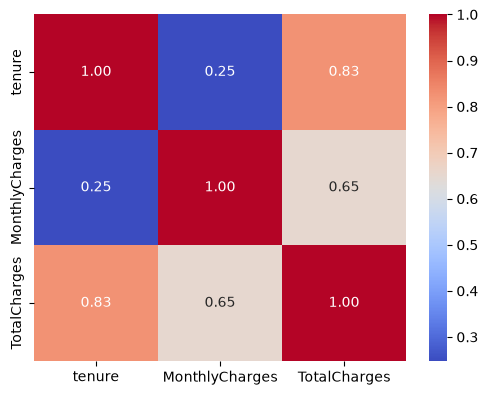

In [16]:
#Mapa de calor con los valores de correlación de Pearson
correlation_matrix = eda_df[num_cols].corr(method='pearson')
plt.figure(figsize=(6, 4.5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f");

### 2.7 Factores de Riesgo Asociados al Churn
Este es el núcleo exploratorio: cruzamos todas las variables demográficas y de servicio contra la variable objetivo. Observamos señales claras de riesgo en clientes con baja antigüedad, contratos mensuales y servicio de fibra óptica (que podría tener problemas de calidad o costo percibido).

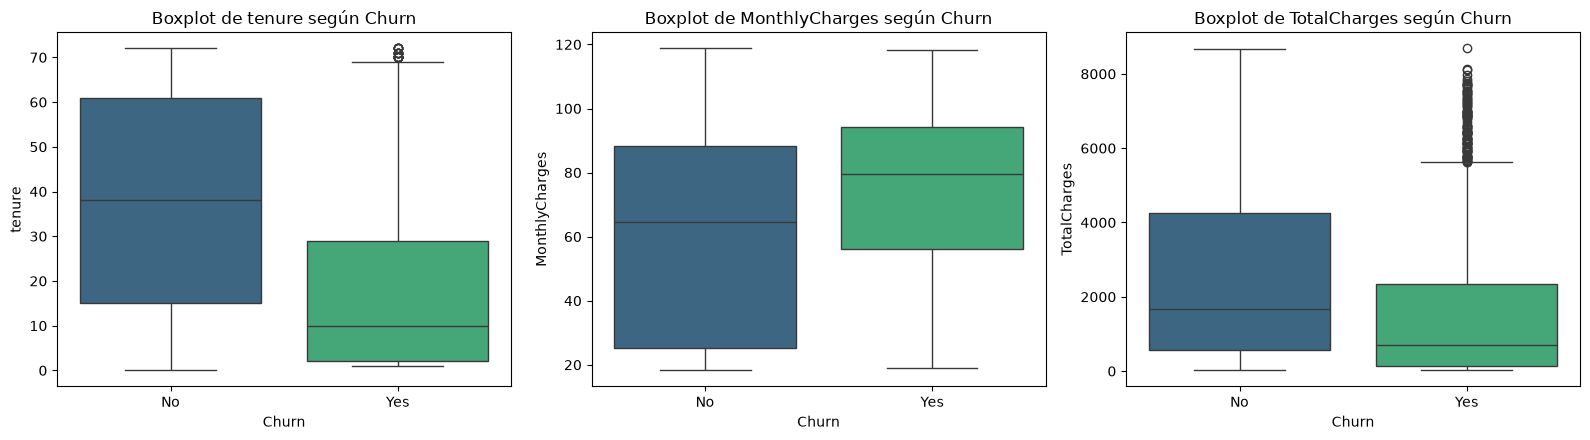

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2555.344141
Yes,17.979133,74.441332,1531.796094


In [17]:
#Variables numéricas: box plots para comparar la distribución de cada variable según los valores de Churn
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(num_cols):
    sns.boxplot(x='Churn', y=col, data=eda_df, ax=axes[i], palette='viridis', hue='Churn')
    axes[i].set_title(f'Boxplot de {col} según Churn')

plt.tight_layout()
plt.show()

#Promedio de cada variable numérica según Churn
eda_df.groupby('Churn')[num_cols].mean()

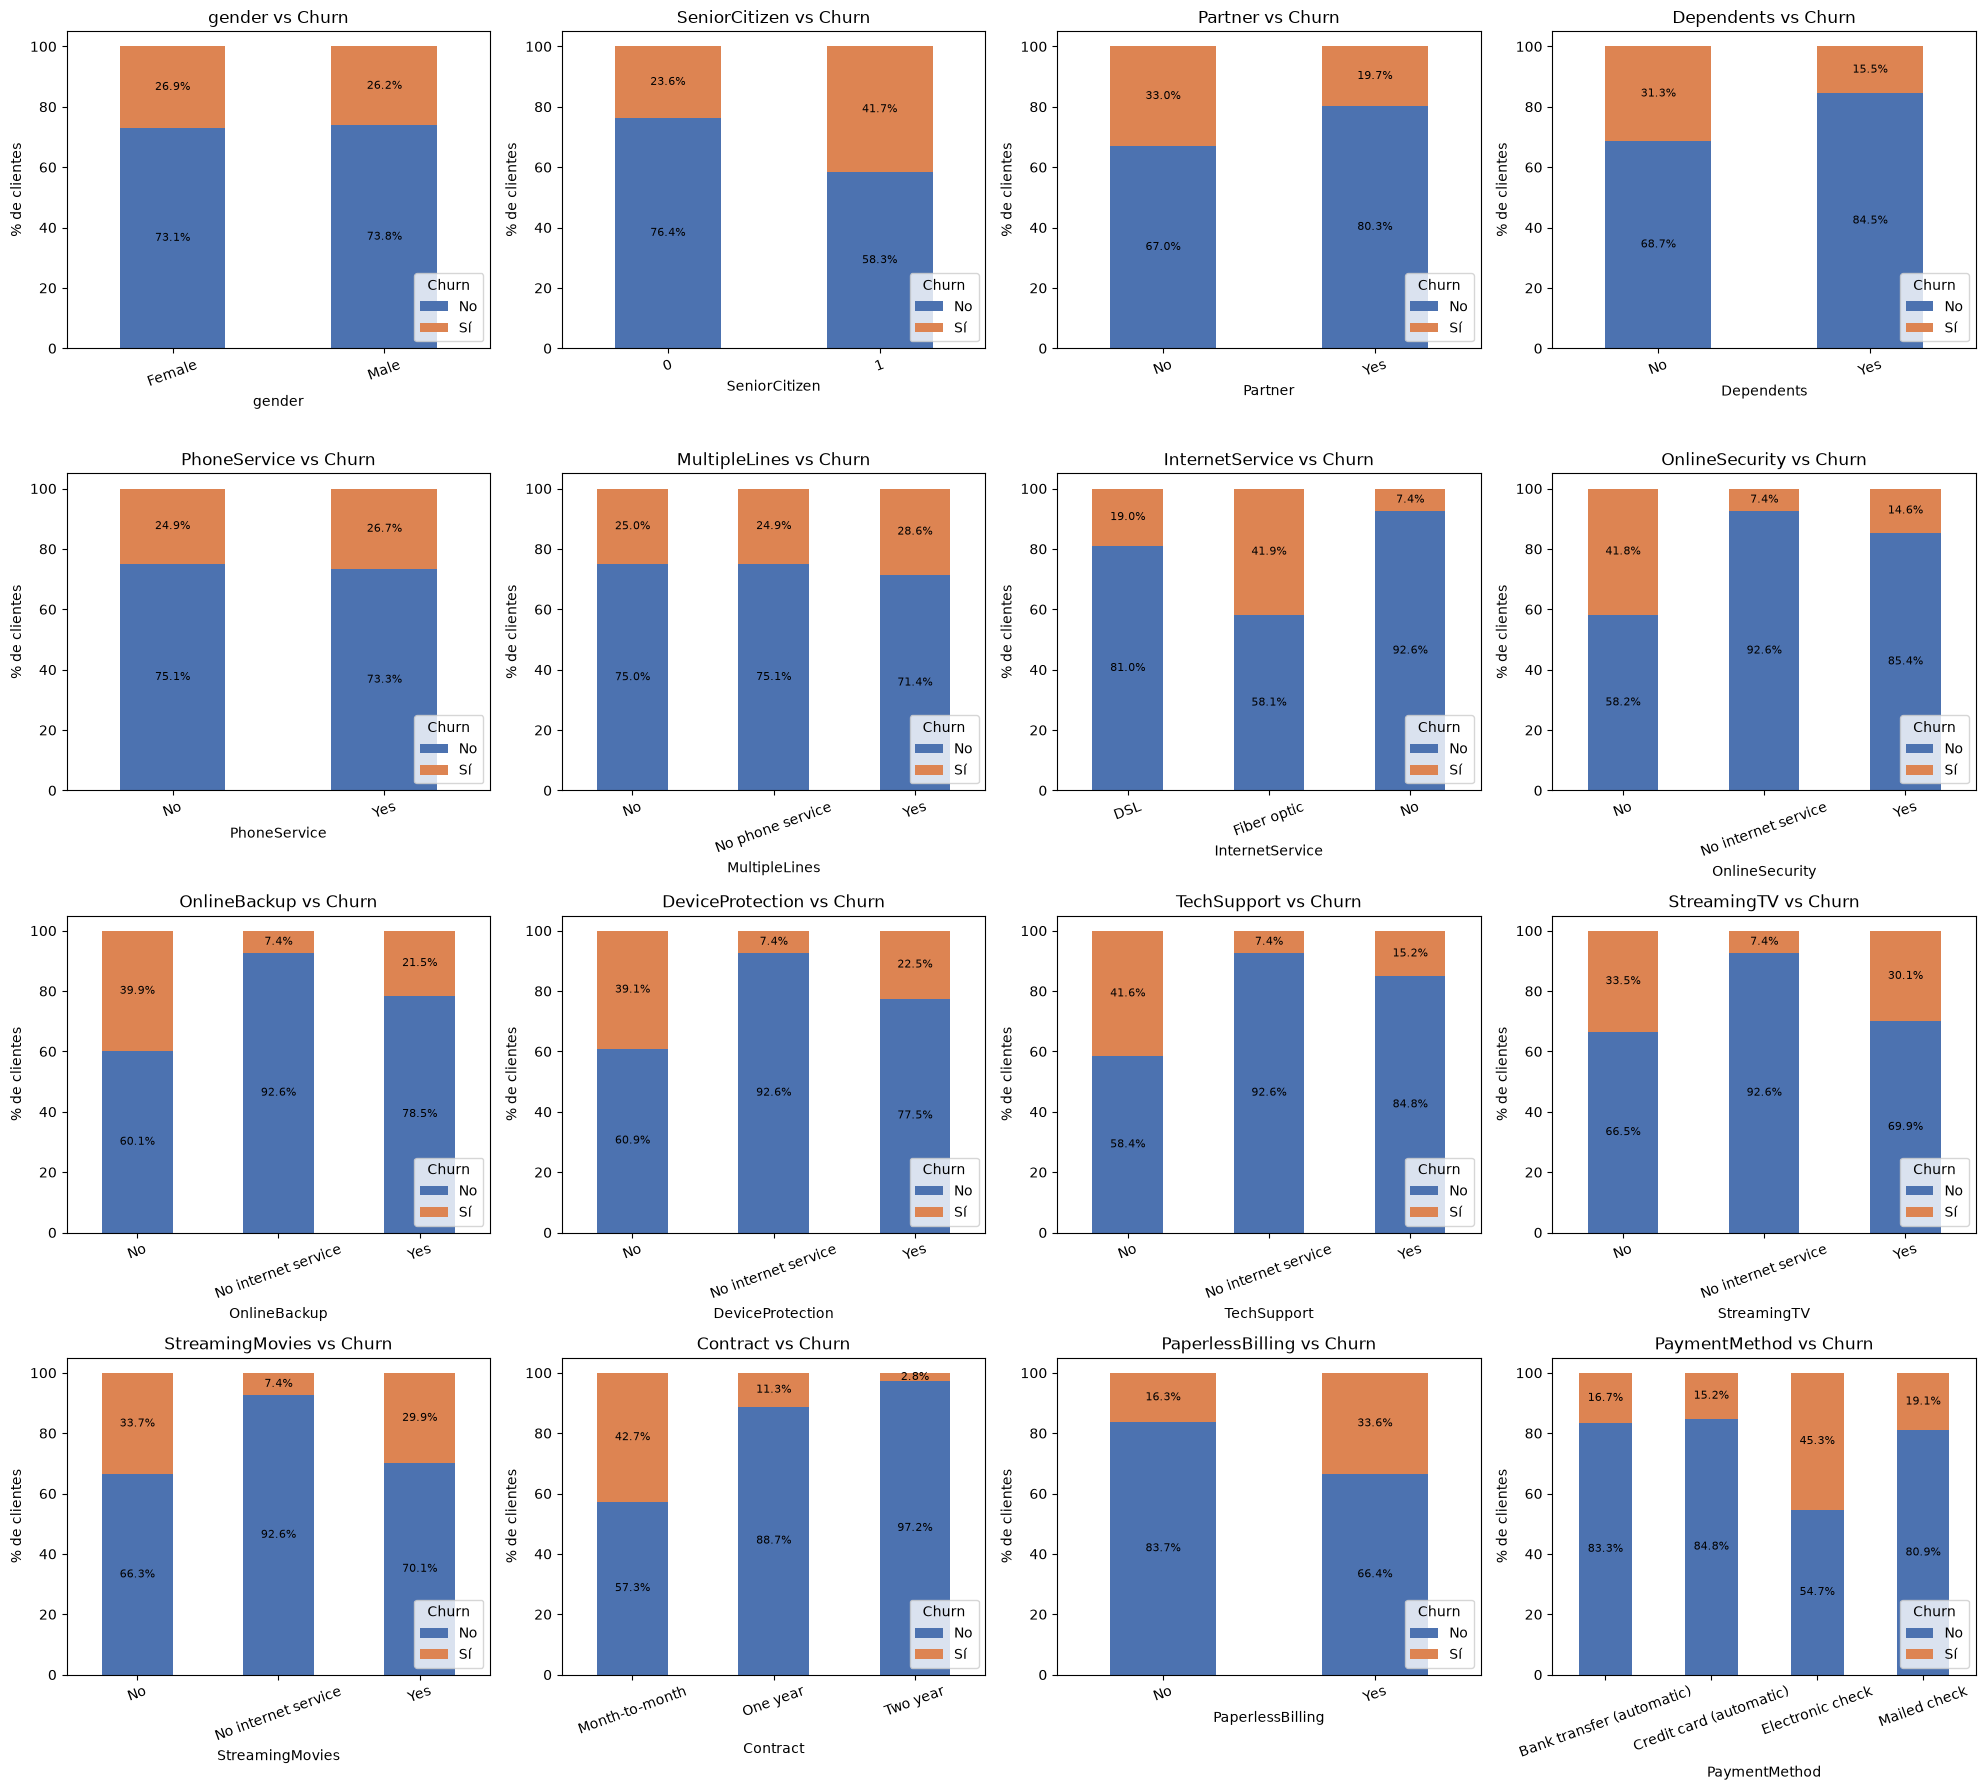

In [18]:
#Variables categóricas: gráficos de barras apiladas con la distribución relativa de Churn dentro de cada categoría
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    contingency_table = pd.crosstab(eda_df[col], eda_df['Churn'], normalize='index') * 100
    contingency_table.plot(kind='bar', stacked=True, ax=axes[i], color=['#4C72B0', '#DD8452'])
    #Se añaden los porcentajes
    for c in axes[i].containers:
        labels = [f'{w.get_height():.1f}%' if w.get_height() > 0 else '' for w in c]
        axes[i].bar_label(c, labels=labels, label_type='center', fontsize=8)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('% de clientes')
    axes[i].set_title(f'{col} vs Churn')
    axes[i].legend(['No', 'Sí'], title='Churn', loc='lower right')
    axes[i].tick_params(axis='x', labelrotation=20)

plt.tight_layout()
plt.show()

In [19]:
#Tasa de abandono (porcentaje de Churn = Yes) en las variables categóricas más relevantes
for col in ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'gender', 'PhoneService']:
    tasa = pd.crosstab(eda_df[col], eda_df['Churn'], normalize='index')['Yes'].sort_values(ascending=False)
    print(f"--- {col} ---")
    print((tasa * 100).round(1).to_string(), "\n")

--- Contract ---
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

--- InternetService ---
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4 

--- PaymentMethod ---
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2 

--- OnlineSecurity ---
OnlineSecurity
No                     41.8
Yes                    14.6
No internet service     7.4 

--- TechSupport ---
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4 

--- gender ---
gender
Female    26.9
Male      26.2 

--- PhoneService ---
PhoneService
Yes    26.7
No     24.9 

